# Import libraries

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.6/383.6 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.8/231.8 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 3.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme()


# machine learning
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier # XG boost
from sklearn.ensemble import RandomForestRegressor # Random Forest
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV # GridSearch CV
import optuna # optuna (Bayesian optimization)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

---

# Viewing dataset

In [ ]:
# connect with google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# load dataset
file_path = '/content/drive/MyDrive/0003. FTU SUBJECTS/010. PHÂN TÍCH DỮ LIỆU/04. CUSTOMER SEGMENTATION PROJECT/02. NOTEBOOK/04. TRANSACTION/02. Predictive Analytics/01. TẠO DATASET/predictive_analytics.csv'
df = pd.read_csv(file_path)
display(df.head())

,customer_id,past_3_years_bike_related_purchases,tenure,Age,postcode,property_valuation,transaction_count,total_spend,avg_spend,std_spend,...,job_industry_category,wealth_segment,deceased_indicator,owns_car,address,state,country,preferred_product_line,preferred_brand,high_value_customer
0,1,93,11.0,72,2016.0,10.0,11.0,9084.45,825.859091,601.942740,...,Health,Mass Customer,N,Yes,060 Morning Avenue,NSW,Australia,Standard,Giant Bicycles,1
1,2,81,16.0,45,2153.0,10.0,3.0,4149.07,1383.023333,620.398494,...,Financial Services,Mass Customer,N,Yes,6 Meadow Vale Court,NSW,Australia,Standard,WeareA2B,0
2,3,61,15.0,71,NaN,8.0,8.0,9888.23,1236.028750,539.899300,...,Property,Mass Customer,N,Yes,NaN,NaN,NaN,Standard,Norco Bicycles,1
3,4,33,7.0,64,4211.0,9.0,2.0,1047.72,523.860000,64.629560,...,IT,Mass Customer,N,No,0 Holy Cross Court,QLD,Australia,Standard,Giant Bicycles,0
4,5,56,8.0,48,2448.0,4.0,6.0,5903.20,983.866667,522.823431,...,Health,Affluent Customer,N,Yes,17979 Del Mar Point,NSW,Australia,Road,Norco Bicycles,0


---

#  Inspect Dataset

In [ ]:
# Inspect Dataset
print(df.info())
print()
print(df.describe().T)
print()
print(df.describe(include='object').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 28 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   customer_id                          3999 non-null   int64  
 1   past_3_years_bike_related_purchases  3999 non-null   int64  
 2   tenure                               3999 non-null   float64
 3   Age                                  3999 non-null   int64  
 4   postcode                             3995 non-null   float64
 5   property_valuation                   3999 non-null   float64
 6   transaction_count                    3999 non-null   float64
 7   total_spend                          3999 non-null   float64
 8   avg_spend                            3999 non-null   float64
 9   std_spend                            3999 non-null   float64
 10  total_profit                         3999 non-null   float64
 11  avg_profit                    

# Xác định features and target

In [ ]:
# Chọn các features để dự đoán
predictors = [
    'Age', 'gender', 'job_industry_category', 'wealth_segment',
    'owns_car', 'property_valuation', 'transaction_count',
    'avg_spend', 'online_order_ratio', 'state'
]

X = df[predictors]
y = df['high_value_customer']

In [ ]:
# Shape
print(f'Shape of X: {X.shape}')
print(f'Shape of y: {y.shape}')

Shape of X: (3999, 10)
Shape of y: (3999,)


In [ ]:
nominal_features = X.select_dtypes(include=['object']).columns
print(nominal_features)

print()
ordinal_features = 'wealth_segment'
# remove
nominal_features = nominal_features.drop(ordinal_features)

Index(['gender', 'job_industry_category', 'wealth_segment', 'owns_car',
       'state'],
      dtype='object')



In [ ]:
print(f'Nominal features: {nominal_features}')
print(f'Ordinal features: {ordinal_features}')

Nominal features: Index(['gender', 'job_industry_category', 'owns_car', 'state'], dtype='object')
Ordinal features: wealth_segment


In [ ]:
# numerical features
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
print(numerical_features)

Index(['Age', 'property_valuation', 'transaction_count', 'avg_spend',
       'online_order_ratio'],
      dtype='object')


In [ ]:
# Standard for Numerical
scaler = StandardScaler()
X[numerical_features] = scaler.fit_transform(X[numerical_features])

# Get dummies with norminal
X = pd.get_dummies(X, columns=nominal_features, drop_first=True)

# Mapping with ordinal
mapping = {
    'High Net Worth': 2,
    'Affluent Customer': 1,
    'Mass Customer': 0
}
X[ordinal_features] = X[ordinal_features].map(mapping)

<ipython-input-11-9a0b343be324>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[numerical_features] = scaler.fit_transform(X[numerical_features])


In [ ]:
# Feature selection với Random Forest
print("Feature selection...")
def select_features_random_forest(X, y, n_features=5):
    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    rf.fit(X, y)

    importances = rf.feature_importances_
    indices = np.argsort(importances)[::-1][:n_features]

    selected_features = X.columns[indices]
    selected_importances = importances[indices]

    feature_importance_df = pd.DataFrame({
        'Feature': selected_features,
        'Importance': selected_importances
    })
    return selected_features, feature_importance_df

selected_features, feature_importance_df = select_features_random_forest(X, y)
print("\nTop 5 Important Features:")
print(feature_importance_df)

Feature selection...

Top 5 Important Features:
              Feature  Importance
0   transaction_count    0.767398
1           avg_spend    0.231373
2                 Age    0.000304
3  online_order_ratio    0.000249
4           state_VIC    0.000198


In [ ]:
# Select features
X = X[selected_features]

In [ ]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Shape
print(f'Shape of X_train: {X_train.shape}')
print(f'Shape of X_test: {X_test.shape}')
print(f'Shape of y_train: {y_train.shape}')
print(f'Shape of y_test: {y_test.shape}')

Shape of X_train: (3199, 5)
Shape of X_test: (800, 5)
Shape of y_train: (3199,)
Shape of y_test: (800,)


---

# Bayesian optimization

In [ ]:
# Define the objective function for Optuna
def objective(trial):
  params = {
      'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
      'n_estimators': trial.suggest_int('n_estimators', 50, 500),
      'max_depth': trial.suggest_int('max_depth', 3, 100),
      'subsample': trial.suggest_float('subsample', 0.6, 1.0),
      'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
      'gamma': trial.suggest_float('gamma', 0.0, 5.0),
      'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 10.0),
      'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 10.0)
  }

  # Train XGBoost model with suggested params
  model = XGBClassifier(
      eval_metric='logloss',
      random_state=42,
      **params
  )
  model.fit(X_train, y_train)

  # Evaluation
  y_pred = model.predict(X_test)
  accuracy = accuracy_score(y_test, y_pred)

  return accuracy

In [ ]:
# Create optuna study
study = optuna.create_study(direction='maximize')

# Optimize the objective function
study.optimize(objective, n_trials=50)

[I 2025-03-15 07:39:57,802] A new study created in memory with name: no-name-727aa814-df43-4626-868f-6766176103c0
[I 2025-03-15 07:39:59,126] Trial 0 finished with value: 0.99375 and parameters: {'learning_rate': 0.10592052764018828, 'n_estimators': 499, 'max_depth': 3, 'subsample': 0.6756967431380261, 'colsample_bytree': 0.87647699802774, 'gamma': 4.371680184143935, 'reg_alpha': 2.7142135461657055, 'reg_lambda': 5.620877408070251}. Best is trial 0 with value: 0.99375.
[I 2025-03-15 07:39:59,510] Trial 1 finished with value: 0.99 and parameters: {'learning_rate': 0.28278135765086254, 'n_estimators': 328, 'max_depth': 37, 'subsample': 0.7560939546899526, 'colsample_bytree': 0.6231046195616898, 'gamma': 3.986216327707007, 'reg_alpha': 8.400208634945933, 'reg_lambda': 8.003598851977928}. Best is trial 0 with value: 0.99375.
[I 2025-03-15 07:39:59,670] Trial 2 finished with value: 0.9925 and parameters: {'learning_rate': 0.2506606301300022, 'n_estimators': 123, 'max_depth': 100, 'subsample

In [ ]:
# Best hyperparameters
best_params = study.best_params
print("Best Hyperparameters:", best_params)

best_accuracy = study.best_value
print("Best Accuracy:", best_accuracy)

Best Hyperparameters: {'learning_rate': 0.17718937999883896, 'n_estimators': 83, 'max_depth': 6, 'subsample': 0.8450973892776121, 'colsample_bytree': 0.6043207436901472, 'gamma': 0.8003275946453797, 'reg_alpha': 7.390353182250751, 'reg_lambda': 3.283857745742227}
Best Accuracy: 1.0


In [ ]:
# Evaluate the best model
best_model = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    **best_params
)
best_model.fit(X_train, y_train)

# Make predictions
y_pred_best = best_model.predict(X_test)

# Evaluate the best model
print(f"Accuracy of best model: {accuracy_score(y_test, y_pred_best):.4f}")

Accuracy of best model: 1.0000


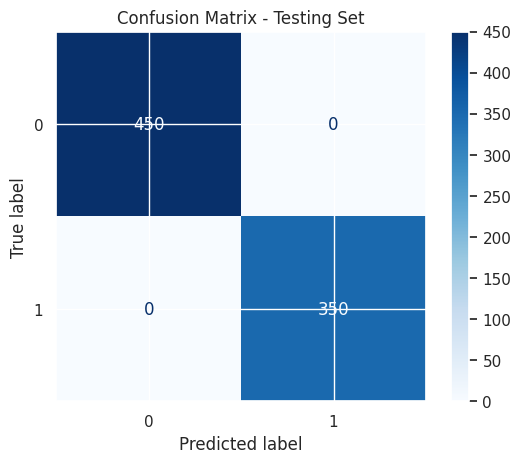

In [ ]:
# Compute confusion matrix
cm_test = confusion_matrix(y_test, y_pred_best)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=best_model.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Testing Set')
plt.show()

In [ ]:
# Classification metrics
print("Classification Report:")
print(classification_report(y_test, y_pred_best))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       450
           1       1.00      1.00      1.00       350

    accuracy                           1.00       800
   macro avg       1.00      1.00      1.00       800
weighted avg       1.00      1.00      1.00       800



In [ ]:
# features importance
importance = best_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("Feature Importance from the best XGBoost:")
print(importance_df)

Feature Importance from the best XGBoost:
              Feature  Importance
0   transaction_count    0.625694
1           avg_spend    0.264985
3  online_order_ratio    0.090224
2                 Age    0.019098
4           state_VIC    0.000000


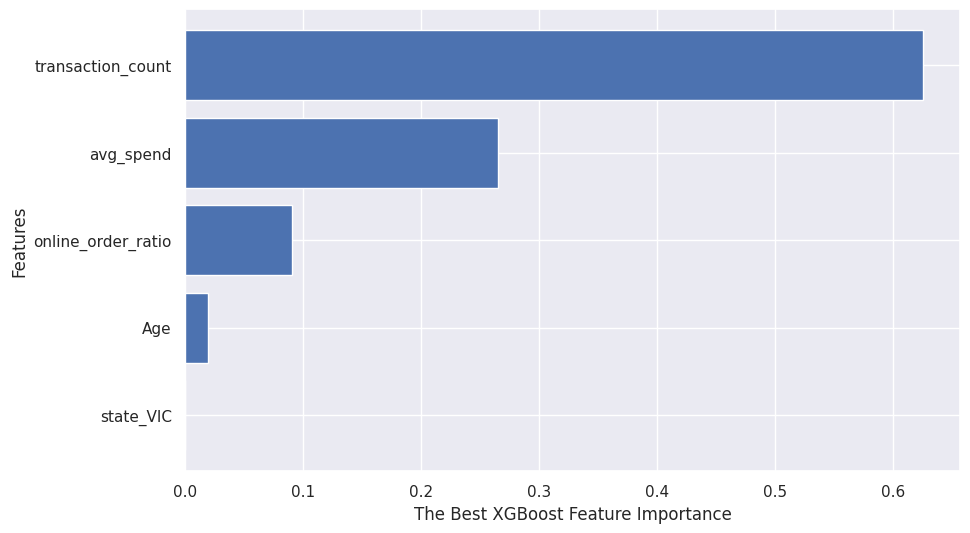

In [ ]:
# Plot features importance
plt.figure(figsize=(10,6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.gca().invert_yaxis()
plt.xlabel("The Best XGBoost Feature Importance")
plt.ylabel("Features")
plt.show()

---

# Phân tích kết quả

## Dự đoán khả năng mua hàng

- **Độ chính xác của mô hình (accuracy)**:
  - Đánh giá mức độ chính xác tổng thể của mô hình trong việc dự đoán khả năng mua hàng.

- **Báo cáo phân loại (classification_report)**:
  - Cung cấp thông tin chi tiết về các chỉ số như **precision**, **recall**, và **f1-score** để hiểu rõ hiệu suất của mô hình trên từng lớp (class).

- **Các yếu tố quan trọng nhất ảnh hưởng đến khả năng mua hàng (feature_importance)**:
  - Xác định và phân tích các yếu tố có tác động lớn nhất đến khả năng mua hàng, giúp hiểu rõ hơn về hành vi khách hàng.